# Step 3 - Features and first models  (18 - 31 Oct)
Call features (PIN requests, urgent words, bank/government claims...), message/email/link features (shorteners, HTTPS, look-alike domains, domain reputation) and three Random Forests: call-only, message-only, combined. Scored on the **validation** set only.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
from toadwatch import config as C
from toadwatch.features import build_features
from toadwatch.modeling import score_all, train_all
from toadwatch.reporting import plot_confusion_matrices, plot_metric_bars
from toadwatch.splitting import load_split
train, val = load_split('train'), load_split('val')
X_train, y_train = build_features(train), train.label
X_val, y_val = build_features(val), val.label
X_train.shape, X_val.shape

((2862, 60), (410, 60))

In [2]:
X_train.describe().T.head(40)

,count,mean,std,min,25%,50%,75%,max
call_pin_request,2862.0,0.136967,0.642301,0.000000,0.000000,0.000000,0.000000,9.000000
call_ssn_request,2862.0,1.109713,2.796584,0.000000,0.000000,0.000000,0.000000,22.000000
call_card_account_number,2862.0,0.564990,1.591595,0.000000,0.000000,0.000000,0.000000,17.000000
call_verify_confirm,2862.0,1.481481,1.819207,0.000000,0.000000,1.000000,2.000000,11.000000
call_press_one,2862.0,0.111111,0.481270,0.000000,0.000000,0.000000,0.000000,6.000000
call_urgent_words,2862.0,0.567785,1.212822,0.000000,0.000000,0.000000,1.000000,11.000000
call_threat_legal,2862.0,0.209644,0.646615,0.000000,0.000000,0.000000,0.000000,11.000000
call_stay_on_line,2862.0,0.118449,0.606053,0.000000,0.000000,0.000000,0.000000,13.000000
call_dont_tell,2862.0,0.001048,0.032365,0.000000,0.000000,0.000000,0.000000,1.000000
call_claims_bank,2862.0,0.323201,1.020592,0.000000,0.000000,0.000000,0.000000,12.000000


## Three versions, same algorithm and settings

In [3]:
models = train_all(X_train, y_train)
scores = score_all(models, X_val, y_val)
scores[['n','accuracy','precision','recall','f1','tn','fp','fn','tp']].round(4)

,n,accuracy,precision,recall,f1,tn,fp,fn,tp
variant,,,,,,,,,
call_only,410,0.9878,0.9854,0.9902,0.9878,203,3,2,202
message_only,410,0.9073,0.9109,0.9020,0.9064,188,18,20,184
combined,410,0.9854,0.9806,0.9902,0.9854,202,4,2,202


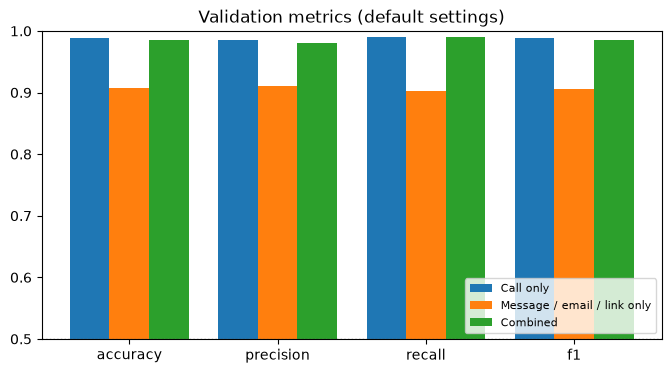

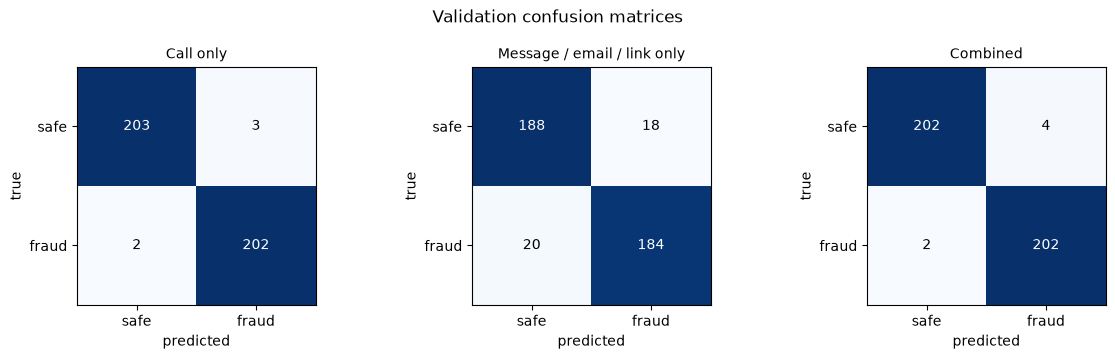

In [4]:
plot_metric_bars(scores, 'Validation metrics (default settings)', 'step3_validation_metrics')
plot_confusion_matrices(scores, 'Validation confusion matrices', 'step3_validation_confusion');

Domain age: `config.USE_DOMAIN_AGE` is off (WHOIS is slow and needs network). The Tranco top-1M rank is used as an offline reputation stand-in; `experiments/ablation_and_shortcuts.py` measures its effect.